# 20장 통합 이론 — 주의, 감정, 정신 질환, 그리고 다른 뇌 이론 (실습)

자유 에너지 원리가 여러 현상을 같은 계산으로 설명한다는 주장을 작은 실험 넷으로 확인한다.

1. 주의는 정밀도다 — 포스너 단서 과제
2. 정밀도가 어긋나면 — 환각과 감각 과부하
3. 헤브 학습은 자유 에너지의 경사 하강이다
4. 내수용 감각과 알로스타시스

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import koreanize_matplotlib  # 한글 글꼴과 마이너스 기호 설정

SEED = 1234
np.random.seed(SEED)
plt.rcParams.update({"figure.figsize": (6.4, 3.2), "figure.dpi": 200,
                     "axes.spines.top": False, "axes.spines.right": False})
print("시드", SEED)

시드 1234


## 1. 주의는 정밀도다 — 포스너 단서 과제

왼쪽과 오른쪽 두 자리 가운데 한 곳에 자극(세기 1)이 나타난다. Hydar 는 걸음마다 두 자리의 잡음 섞인 감각 y 를 받고, 6장의 캡슐처럼 경사 하강으로 자극의 세기 μ 를 추론한다. 자극 자리의 μ 가 0.5 를 넘는 걸음을 반응 시간으로 잰다. 시행 전에 화살표 단서가 한쪽을 가리키면 Hydar 는 그 자리의 감각 정밀도를 g 배로 올리고 반대쪽은 g 로 나눈다. 단서가 맞는 시행(유효), 틀린 시행(무효), 자극이 없는 시행(잡기)을 견준다.

g =   1:  반응 시간 유효   14.7  무효   14.7  (무효 − 유효   0.0)   잡기 시행 오경보 0.069
g = 1.5:  반응 시간 유효    9.1  무효   23.9  (무효 − 유효  14.8)   잡기 시행 오경보 0.343
g =   2:  반응 시간 유효    6.6  무효   35.1  (무효 − 유효  28.5)   잡기 시행 오경보 0.773
g =   3:  반응 시간 유효    4.1  무효   64.1  (무효 − 유효  60.0)   잡기 시행 오경보 0.993


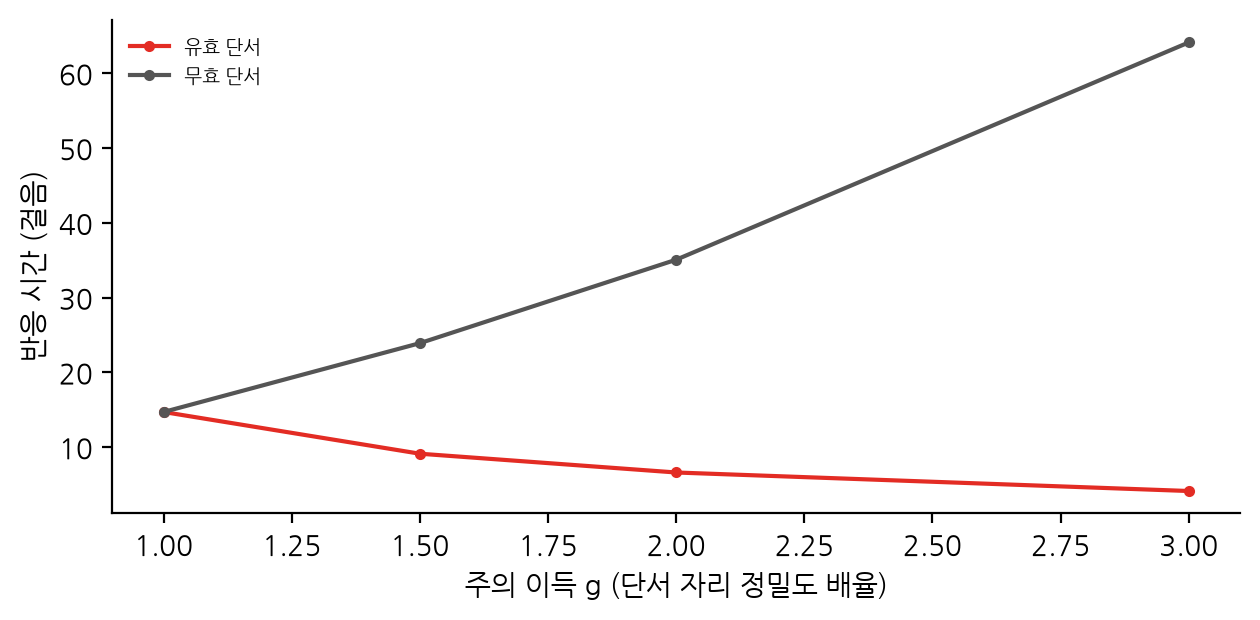

In [2]:
def posner(gain, kind, n=2000, seed=0, kappa=0.05, T=400, thr=0.5, Pp=0.25):
    rng = np.random.default_rng(seed); rts = []; fa = 0
    for k in range(n):
        side = rng.integers(2)
        cued = side if kind == "유효" else 1 - side
        Ps = np.ones(2); Ps[cued] *= gain; Ps[1 - cued] /= gain     # 기대 감각 정밀도
        x = np.zeros(2)
        if kind != "잡기":
            x[side] = 1.0
        mu = np.zeros(2); rt = T
        for t in range(T):
            y = x + rng.normal(0, 1, 2)
            mu += kappa * (Ps * (y - mu) - Pp * mu)                # 감각 오차 − 사전 오차 (사전 기대 0)
            if kind == "잡기":
                if mu.max() > thr:
                    fa += 1; break
            elif mu[side] > thr:
                rt = t; break
        rts.append(rt)
    return (fa / n) if kind == "잡기" else np.mean(rts)

gains = [1, 1.5, 2, 3]
res = {kind: [posner(g, kind) for g in gains] for kind in ["유효", "무효", "잡기"]}
for g, v, iv, c in zip(gains, res["유효"], res["무효"], res["잡기"]):
    print(f"g = {g:3}:  반응 시간 유효 {v:6.1f}  무효 {iv:6.1f}  (무효 − 유효 {iv - v:5.1f})   잡기 시행 오경보 {c:.3f}")

fig, ax = plt.subplots()
ax.plot(gains, res["유효"], "o-", color="#E32C24", ms=3, label="유효 단서")
ax.plot(gains, res["무효"], "o-", color="#555555", ms=3, label="무효 단서")
ax.set_xlabel("주의 이득 g (단서 자리 정밀도 배율)"); ax.set_ylabel("반응 시간 (걸음)")
ax.legend(fontsize=7, frameon=False); plt.tight_layout(); plt.show()

## 2. 정밀도가 어긋나면

Hydar 는 자극이 있을 것이라고 기대한다(사전 기대 η = 1). 실제로는 시행의 절반에만 자극이 있다. 감각 정밀도 Πs = 1 은 그대로 두고 사전 정밀도 Πp 를 바꾸며, 자극이 없을 때 「보았다」고 하는 오경보율과 자극이 있을 때의 적중률을 잰다.

In [3]:
rng = np.random.default_rng(SEED)
n = 20000
y_absent = rng.normal(0, 1, n)
y_present = 1 + rng.normal(0, 1, n)
ratios = [0.1, 0.3, 1, 3, 10]
print(f"{'Πp/Πs':>6s}{'오경보':>8s}{'적중':>8s}")
for r in ratios:
    Pp, Ps = r, 1.0
    post = lambda y: (Pp * 1.0 + Ps * y) / (Pp + Ps)
    print(f"{r:6.1f}{np.mean(post(y_absent) > 0.5):8.3f}{np.mean(post(y_present) > 0.5):8.3f}")

 Πp/Πs     오경보      적중
   0.1   0.322   0.713
   0.3   0.360   0.747
   1.0   0.493   0.845
   3.0   0.838   0.979
  10.0   1.000   1.000


같은 문제를 추정 오차로 본다. 실제 세계는 x ~ N(1, 1), y = x + N(0, 1) 이라 참 정밀도 비는 1 이다. Hydar 가 가정한 비 Πp/Πs 를 0.03 에서 30 까지 바꾸며 깊이 추정의 평균 제곱 오차를 잰다.

Πp/Πs =  0.032:  MSE 0.944
Πp/Πs =  0.178:  MSE 0.744
Πp/Πs =  1.000:  MSE 0.499
Πp/Πs =  5.623:  MSE 0.748
Πp/Πs = 31.623:  MSE 0.949


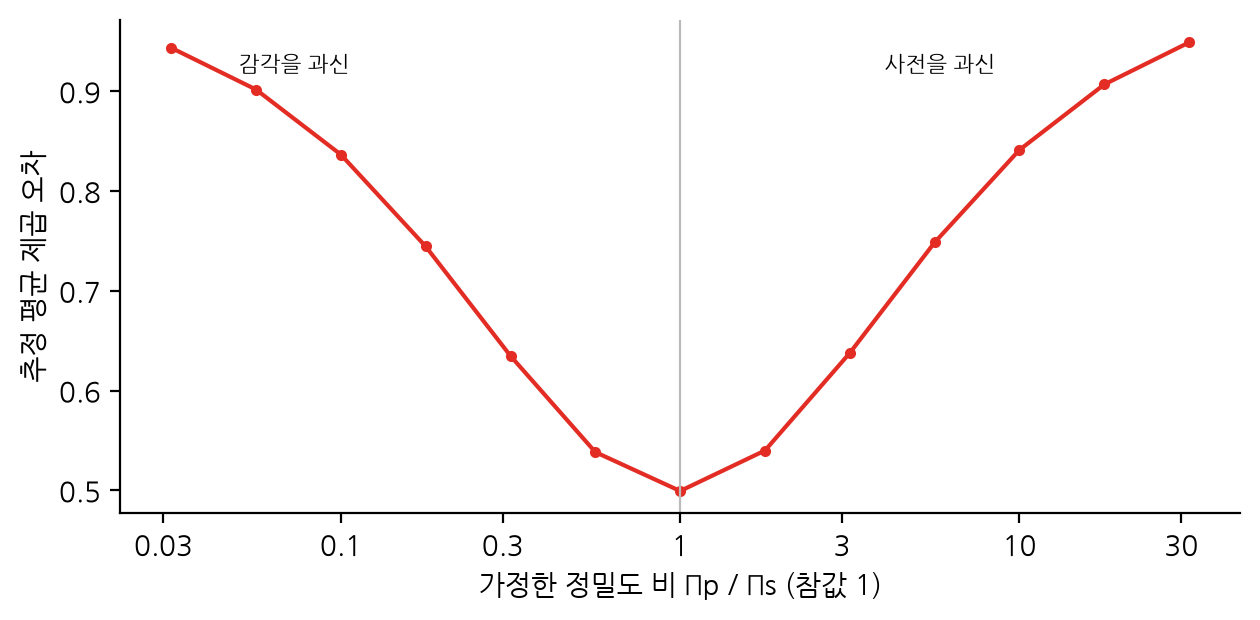

In [4]:
x = 1 + rng.normal(0, 1, n)
y = x + rng.normal(0, 1, n)
rs = np.logspace(-1.5, 1.5, 13)
mse = [np.mean(((r * 1.0 + y) / (r + 1) - x) ** 2) for r in rs]
for r, m in zip(rs[::3], mse[::3]):
    print(f"Πp/Πs = {r:6.3f}:  MSE {m:.3f}")
fig, ax = plt.subplots()
ax.semilogx(rs, mse, "o-", color="#E32C24", ms=3)
ax.set_xticks([0.03, 0.1, 0.3, 1, 3, 10, 30]); ax.set_xticklabels(["0.03", "0.1", "0.3", "1", "3", "10", "30"]); ax.minorticks_off()
ax.axvline(1, color="#BBBBBB", lw=0.8)
ax.text(0.05, max(mse) * 0.97, "감각을 과신", fontsize=8); ax.text(4, max(mse) * 0.97, "사전을 과신", fontsize=8)
ax.set_xlabel("가정한 정밀도 비 Πp / Πs (참값 1)"); ax.set_ylabel("추정 평균 제곱 오차")
plt.tight_layout(); plt.show()

## 3. 헤브 학습은 자유 에너지의 경사 하강이다

감각 y = θ·x + z 에서 연결 세기 θ 를 모른다. 자유 에너지 F = ½Πy(y − θμx)² 를 θ 로 미분하면 갱신은 Δθ = κΠy·εy·μx 다. 시냅스 뒤쪽의 예측 오차와 시냅스 앞쪽의 활동을 곱한 꼴이다.

In [5]:
rng = np.random.default_rng(SEED)
theta_true, theta, kappa, Py = 2.0, 0.0, 0.02, 1.0
hist = []
for t in range(1500):
    mu_x = rng.normal(0, 1)                    # 앞 뉴런의 활동 (원인에 대한 믿음)
    y = theta_true * mu_x + rng.normal(0, 0.5)
    eps_y = y - theta * mu_x                   # 뒤 뉴런의 예측 오차
    theta += kappa * Py * eps_y * mu_x         # 앞 활동 × 뒤 오차
    hist.append(theta)
print(f"참 θ = {theta_true},  100 걸음 뒤 {hist[99]:.3f},  500 걸음 뒤 {hist[499]:.3f}")
print(f"마지막 1000 걸음의 평균 {np.mean(hist[500:]):.3f},  표준편차 {np.std(hist[500:]):.3f}")

참 θ = 2.0,  100 걸음 뒤 1.767,  500 걸음 뒤 1.974
마지막 1000 걸음의 평균 1.982,  표준편차 0.050


## 4. 내수용 감각과 알로스타시스

Hydar 의 에너지 e 는 설정값 0 근처에 있어야 한다. 100 걸음마다 20 걸음 동안 헤엄치며 에너지를 0.3 씩 쓴다. 항상성 제어는 지금의 내수용 예측 오차 (0 − e) 에만 반응한다. 알로스타시스 제어는 몸에 대한 생성 모델로 곧 닥칠 소비를 예측해 미리 먹는다. 세 번째 Hydar 는 일정이 50 걸음 밀린 것을 모르고 옛 일정대로 예측한다.

항상성    : 설정값에서 벗어난 RMS 1.024,  최저 -2.695,  최고 0.079
알로스타시스 : 설정값에서 벗어난 RMS 0.174,  최저 -0.499,  최고 0.079
틀린 예측  : 설정값에서 벗어난 RMS 1.268,  최저 -2.684,  최고 2.181


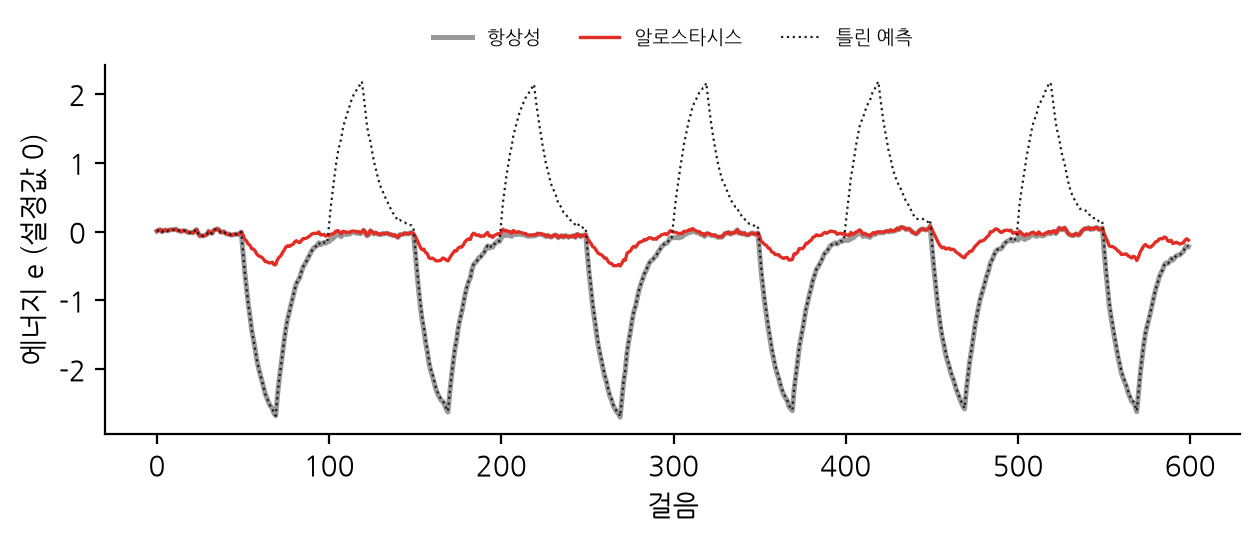

In [6]:
def energy(mode, T=600, seed=1, k=0.1):
    rng = np.random.default_rng(seed)
    demand = np.zeros(T)
    for s in range(50, T, 100):
        demand[s:s + 20] = 0.3
    expected = np.zeros(T)                       # 몸에 대한 생성 모델이 예측한 소비
    shift = 50 if mode == "틀린 예측" else 0
    for s in range(50 + shift, T, 100):
        expected[s:s + 20] = 0.25
    e, es = 0.0, []
    for t in range(T):
        u = k * (0 - e)                          # 지금의 내수용 예측 오차에 반응
        if mode != "항상성":
            u += expected[t]                     # 예측된 소비를 미리 메운다
        e += u - demand[t] + rng.normal(0, 0.02)
        es.append(e)
    return np.array(es)

fig, ax = plt.subplots(figsize=(6.4, 2.8))
styles = {"항상성": dict(color="#999999", lw=1.8), "알로스타시스": dict(color="#E32C24", lw=1.2),
          "틀린 예측": dict(color="#1C1C1A", lw=0.8, ls=":")}
for mode in ["항상성", "알로스타시스", "틀린 예측"]:
    es = energy(mode)
    print(f"{mode:7s}: 설정값에서 벗어난 RMS {np.sqrt(np.mean(es ** 2)):.3f},  최저 {es.min():.3f},  최고 {es.max():.3f}")
    ax.plot(es, label=mode, **styles[mode])
ax.set_xlabel("걸음"); ax.set_ylabel("에너지 e (설정값 0)")
ax.legend(fontsize=7, frameon=False, ncol=3, loc="lower center", bbox_to_anchor=(0.5, 1.0)); plt.tight_layout(); plt.show()